# T05 — Trading in a session

*How does my own order enter a market that keeps moving?*

**What you will learn**

- how a `Session` replays other traders' orders and lets you add your own on top;
- how the market clock runs from gate opening to gate closure, and what `done` means;
- what one step does, and how to read its `FillReport` and the top of the book;
- how to choose a tape and cancel an order between steps;
- four pitfalls, each shown with its fix.

**What you need**

- Previous tutorials: [T01](T01_first_contract.ipynb) (the order book) and [T04](T04_synthetic_flow.ipynb) (tapes) help, but are not required.
- Run time: about 4 minutes on a central processing unit (CPU). Almost all of it is compiling: this tutorial builds three session configurations, and each one compiles its step once, in about a minute.
- Network: no.

## Setup

Imports, the device (CPU by default), the seeds, the figure style and the repository root.
Every data path is built from `ROOT`, never relative to this folder.

In [1]:
# Setup: device, repository root, seeds and the figure style. Run this cell first.
import os
from pathlib import Path

os.environ.setdefault("JAX_PLATFORMS", "cpu")  # CPU by default; export JAX_PLATFORMS=cuda before Jupyter for a GPU

# The repository root is the first folder above this notebook that holds pyproject.toml.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
DATA_DIR = ROOT / "data" / "rawOMIE"  # every data path starts here (ignored by git), never under tutorials/

import jax
import matplotlib.pyplot as plt
import numpy as np

SEED = 0  # fixed seeds: a re-run gives the same market results
rng = np.random.default_rng(SEED)
key = jax.random.PRNGKey(SEED)

# Figure style, the same five lines in every tutorial: buy, sell, a third series, neutral.
BUY, SELL, THIRD, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#9a9893"
plt.rcParams.update({"figure.figsize": (7, 3.2), "figure.dpi": 110, "savefig.dpi": 110, "font.size": 9.5,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e1", "legend.frameon": False, "axes.titlesize": 10.5,
                     "axes.titleweight": "bold", "axes.titlelocation": "left"})
print(f"JAX {jax.__version__}, backend: {jax.default_backend()}")

JAX 0.6.2, backend: cpu


## 1. Replay and participation

OMIE (Operador del Mercado Ibérico de Energía) runs the continuous intraday market (CID) of Spain and
Portugal. Each 15-minute delivery period is a separate contract, traded continuously from gate opening
to gate closure. (Trading pauses for about 20 minutes during each intraday auction; the simulator does not model these
pauses.) A `Session` simulates one contract over that window.

> **Concept — replay and participation.** Other traders' orders come from a *tape*: a time-ordered list
> of orders, recorded from the real market or made up ([T04](T04_synthetic_flow.ipynb)). The session
> *replays* the tape into the order book, a few orders at a time. You *participate* by adding your own
> orders between those slices. Your orders trade against the replayed ones under the same rules, but the
> tape does not react to you: the other traders keep sending the orders they sent. So your trades can take
> liquidity that another trader took in the real market, and the tape still sends that trader's later orders as if
> nothing had changed. Real tapes also lack cancellations ([Limitations](../docs/limitations.md#data)).

The [README quickstart](../README.md#quickstart) is the shortest complete session; this tutorial takes it apart step
by step.

`Session()` with no argument uses two short built-in tapes. Building a session compiles nothing yet.

In [2]:
import time

import jax.numpy as jnp

from omiecid_simulator.jaxomiecid.omie_tape_synth import TapeBuilder, stack_tapes
from omiecid_simulator.omiecid.omie_session import AGENT_TRADER_ID, AgentOrder, Session
from omiecid_simulator.omiecid.order_types import Side

builtin = Session()
print(f"built-in set: {builtin.n_tapes} tapes of {builtin.n_orders_padded} rows, "
      f"at most {builtin.steps_per_episode} steps")

built-in set: 2 tapes of 22 rows, at most 6 steps


Six steps are too short to watch a market move, so we build two longer tapes. The helper below draws
a random order flow around a drifting reference price, one order every 15 seconds after gate opening.
Most orders rest in the book; a share `cross_share` of them is priced through the reference price,
so they usually trade on arrival. It is the same kind of tape as in T04, written out here so that this
notebook reads on its own.

- The **calm** tape has 240 orders, of which about one in ten crosses.
- The **busy** tape has 200 orders, half of them crossing, and then a *closing rush*: 40 more orders in the
  last 40 seconds before gate closure. We need it for the pitfalls of section 6.

Quantities are power in megawatts (MW); prices are in euros per megawatt-hour (EUR/MWh).

`stack_tapes` then puts the two tapes in one array, a *tape set*, and fills the shorter one up with *padding rows*: empty rows, with order id and time $\le 0$, that the engine skips ([T04](T04_synthetic_flow.ipynb)).

In [3]:
def make_tape(seed, n_orders=240, spacing_s=15, cross_share=0.1, rush=0):
    # A random order flow around a drifting reference price, one order every spacing_s seconds after
    # gate opening; rush > 0 adds that many orders, one per second, just before the end of the hour.
    rng = np.random.default_rng(seed)
    tb = TapeBuilder(timestamp_step=spacing_s, first_timestamp=spacing_s)
    reference = 50.0
    for i in range(n_orders + rush):
        reference += rng.normal(0, 0.15)  # EUR/MWh
        side = int(rng.integers(2))
        away = -1.0 if side == Side.BUY else 1.0  # a resting buy sits below the reference, a sell above
        gap = -rng.uniform(0.1, 0.6) if rng.random() < cross_share else rng.uniform(0.1, 1.5)
        ts = None if i < n_orders else 3600 - rush + 1 + (i - n_orders)  # seconds after gate opening
        tb.add(side=side, price_eur=round(reference + away * gap, 1), qty_mw=float(rng.integers(1, 6)),
               timestamp=ts)
    return tb.build()


calm = make_tape(seed=6)
busy = make_tape(seed=4, n_orders=200, cross_share=0.5, rush=40)
tapes = stack_tapes([calm, busy])  # one tape set: tape 0 is calm, tape 1 is busy
for name, tape in (("calm", calm), ("busy", busy)):
    ts = tape[tape[:, 6] > 0, 6]  # column 6 is the timestamp; padding rows have none
    print(f"{name} tape: {ts.size} orders, from {ts.min() / 60:.2f} to {ts.max() / 60:.2f} min after opening")
print(f"tape set shape: {tapes.shape} (tapes, rows with padding, columns)")

calm tape: 240 orders, from 0.25 to 60.00 min after opening
busy tape: 240 orders, from 0.25 to 60.00 min after opening
tape set shape: (2, 256, 13) (tapes, rows with padding, columns)


## 2. The market clock

> **Concept — gate opening and gate closure.** All contracts of a delivery day open together at the
> gate opening time (GOT), about 15:20 on the day before delivery. Each contract stops trading at its
> gate closure time (GCT), one hour before its delivery hour starts. A session measures time in minutes
> after GOT, so it starts at 0, and it is over when the clock reaches GCT: that is the flag `done`.

The clock is computed from the timestamps of the tape orders replayed so far. The session has two
clock modes:

- **`span_scaled`** (the default, meant for synthetic tapes). It assumes that the timestamps are seconds
  after GOT, spread over $[0, S]$, where $S$ is `tape_seconds_span` (by default the largest timestamp of
  the whole tape set). It stretches that interval onto $[0, \mathrm{gct}]$ minutes, where $\mathrm{gct}$
  is `gct_minutes_from_got`. After slice $k$, whose largest timestamp is $m_k$, the clock reads
  $t_k = \max\left(t_{k-1},\ \mathrm{round}(m_k \cdot \mathrm{gct} / S)\right)$, rounded to whole minutes.
- **`got_relative`** (meant for real OMIE data). The timestamps are clock times, in seconds after midnight
  of the day before delivery, and the clock reads $t = \lfloor (m_k - g) / 60 \rfloor$ minutes, where
  $g$ is gate opening in the same frame (`got_seconds`). When the tape runs out, the clock jumps to gate
  closure. Section 6.4 uses it.

Our tapes are synthetic, so we keep the default. Here $S = 3600$ s and $\mathrm{gct} = 60$ min: one
hour of tape becomes one hour of session. The 60 minutes are only a convenient default for synthetic
tapes. A real contract trades much longer: contract $k$ is open for $460 + 60\lfloor k/4 \rfloor$
minutes, from 460 minutes (7 h 40 min) for the first contract of the day to 1,840 minutes for the last.

In [4]:
session = Session({"tapes": tapes, "orders_per_step": 4})
print(f"clock mode: {session.session_clock}")
print(f"gate closure: {session.gct_minutes_from_got} min after opening; S = {session.tape_seconds_span:.0f} s")
print(f"orders replayed per step: {session.orders_per_step}; steps at most: {session.steps_per_episode}")

clock mode: span_scaled
gate closure: 60 min after opening; S = 3600 s
orders replayed per step: 4; steps at most: 64


## 3. One step

> **Concept — one step.** A call to `session.step(key, state, order)` does three things, in order:
> 1. **Background.** It replays the next `orders_per_step` orders of the tape into the book.
> 2. **Your order.** If you pass one, the session gives it an order id and stamps it with the book's
>    next arrival number. Your order therefore queues *behind* every order that arrived before it,
>    at the same price (price-time priority, see [T01](T01_first_contract.ipynb)).
> 3. **Clock.** The clock advances, and `done` tells you whether gate closure is reached.

Your order is decided before the step, from the book as it was after the previous step, but it
reaches the book after this step's background orders. Those orders may move the touch (the best bid and the best ask) in between: an
order priced at the best ask can find that ask gone and rest instead, and an order priced at the best
bid can find a seller already there and trade at once.

You choose only the economic fields of your order (side, price, quantity, order type). Passing `None`
means "no order this step".

`reset` starts a session at GOT with an empty book. It draws one tape of the set at random; to replay a
given tape, replace `tape_idx` in the state. The state is a value: every call returns a new state.

The first call to `step` compiles it, which takes about a minute. Later calls take milliseconds.

In [5]:
state = session.reset(key).replace(tape_idx=jnp.int32(0))  # the calm tape
print(f"after reset: clock {int(state.time)} min, tape {int(state.tape_idx)}, next tape row {int(state.tape_cursor)}")

started = time.perf_counter()
state, report, done = session.step(key, state, None)  # no order of our own; compiles the step
tob = session.top_of_book(state)
print(f"first step took {time.perf_counter() - started:.0f} s (compiling included)")
print(f"after step 0: clock {int(state.time)} min, next tape row {int(state.tape_cursor)}, done {bool(done)}")
print(f"best bid {float(tob.p_bid):.2f} EUR/MWh ({float(tob.q_bid):.1f} MW), "
      f"best ask {float(tob.p_ask):.2f} EUR/MWh ({float(tob.q_ask):.1f} MW)")

after reset: clock 0 min, tape 0, next tape row 0


first step took 37 s (compiling included)
after step 0: clock 1 min, next tape row 4, done False
best bid 50.60 EUR/MWh (1.0 MW), best ask 50.80 EUR/MWh (2.0 MW)


`top_of_book` returns the anonymous best bid and best ask, the mid price, and the visible quantity at
each. An empty side reads `has_bid` (or `has_ask`) false and price 0.0. The `FillReport` describes what
happened to *you* during the step:

| Field | Meaning |
|---|---|
| `submitted`, `order_id` | whether the step carried your order, and the id it received |
| `submit.accepted`, `submit.traded`, `submit.trade_qty`, `submit.trade_price` | what your new order did on arrival (MW, EUR/MWh) |
| `passive_qty_signed`, `passive_value_eur` | your *resting* orders that other orders filled during the step |
| `inventory_delta`, `cash_delta_eur` | the change of your position (MW, positive on a buy) and of your cash (EUR, positive on a sale) |
| `trades_saturated` | the book's trade buffer is full (section 6.1) |

The [Sessions guide](../docs/sessions.md#fillreport) lists every field.

## 4. A whole session with your own orders

We now play the calm tape to the end and send four orders of 1 MW, each priced relative to the touch at the moment we send it:

| Step | Order | Expected outcome |
|---|---|---|
| 5 | buy at the best ask | trades at once |
| 9 | buy 0.50 EUR/MWh below the best bid | rests, and trades if the price falls to it |
| 30 | sell 0.30 EUR/MWh above the best ask | rests, and trades if the price rises to it |
| 45 | sell at the best bid | trades at once |

The expected outcomes assume that the touch does not move during the step's background replay
(section 3). On this tape it does not, for any of the four orders.

To know when a resting order trades, we list our own resting orders after every step. That is a
book-level call (`ContractBook.get_agent_orders`), so we build a `ContractBook` for the session's
contract once. Its contract fields do not matter here; it only needs to be open. We cancel nothing in this
run, so an order that leaves the list has traded. A partly filled order would stay in the list with its
remainder; our 1 MW orders fill whole here.

In [6]:
from omiecid_simulator.omiecid.contract import Contract, ContractStatus
from omiecid_simulator.omiecid.contract_book import ContractBook

book = ContractBook(Contract(contract_id=0, delivery_start_minutes=120, delivery_end_minutes=135,
                             gct_minutes=60, status=ContractStatus.OPEN),
                    session.product_config, session.market_config)


def resting_ids(state):
    # The ids of our orders that still rest in the book.
    return {o.order_id for o in book.get_agent_orders(state.book, AGENT_TRADER_ID)}


plan = {5: (Side.BUY, "ask", 0.0), 9: (Side.BUY, "bid", -0.5),
        30: (Side.SELL, "ask", 0.3), 45: (Side.SELL, "bid", 0.0)}

state = session.reset(key).replace(tape_idx=jnp.int32(0))
done, step = False, 0
clock_main = []  # the session's clock after each step
touch = []    # (best bid, best ask) after each step; NaN when a side is empty
orders = {}   # order id -> submission step, side, limit price, step at which it filled (None if never)
while not done:
    tob = session.top_of_book(state)
    order = None
    if step in plan:
        side, reference, offset = plan[step]
        limit = (float(tob.p_ask) if reference == "ask" else float(tob.p_bid)) + offset
        order = AgentOrder.create(side=side, price=round(limit, 2), quantity=1.0)
    state, report, done = session.step(key, state, order)
    done = bool(done)
    clock_main.append(int(state.time))
    tob = session.top_of_book(state)
    touch.append((float(tob.p_bid) if tob.has_bid else np.nan, float(tob.p_ask) if tob.has_ask else np.nan))
    if bool(report.submitted):
        orders[int(report.order_id)] = {"step": step, "side": int(order.side), "price": float(order.price),
                                        "end": None}
    still_resting = resting_ids(state)
    for oid, o in orders.items():
        if o["end"] is None and oid not in still_resting:
            o["end"] = step
    if bool(report.submitted) or float(report.passive_qty_signed) != 0.0:
        print(f"step {step:2d}, {int(state.time):2d} min: "
              f"new order traded {float(report.submit.trade_qty):.1f} MW, "
              f"resting orders traded {float(report.passive_qty_signed):+.1f} MW, "
              f"cash change {float(report.cash_delta_eur):+7.3f} EUR")
    step += 1

last_step = step - 1
print(f"done after step {last_step}, clock {int(state.time)} min")

step  5,  6 min: new order traded 1.0 MW, resting orders traded +0.0 MW, cash change -12.525 EUR


step  9, 10 min: new order traded 0.0 MW, resting orders traded +0.0 MW, cash change  +0.000 EUR


step 21, 22 min: new order traded 0.0 MW, resting orders traded +1.0 MW, cash change -12.225 EUR
step 30, 31 min: new order traded 0.0 MW, resting orders traded +0.0 MW, cash change  +0.000 EUR


step 45, 46 min: new order traded 1.0 MW, resting orders traded +0.0 MW, cash change +12.175 EUR


done after step 59, clock 60 min


The buy at step 5 and the sell at step 45 traded on arrival: they crossed the book. Your resting orders
are filled *passively*, when a later tape order crosses them: the step-9 buy waited until the price fell
to it. A positive quantity is a buy, and buying costs cash.

In [7]:
for oid, o in orders.items():
    side = "buy " if o["side"] == Side.BUY else "sell"
    if o["end"] == o["step"]:
        outcome = "traded at once"
    elif o["end"] is not None:
        outcome = f"rested, traded at step {o['end']}"
    else:
        outcome = "still resting at gate closure"
    print(f"order {oid}: {side} 1.0 MW at {o['price']:.2f} EUR/MWh, sent at step {o['step']:2d}: {outcome}")
print(f"position {float(state.agent_inventory[0]):+.1f} MW, cash {float(state.agent_cash[0]):+.3f} EUR")

order 2000000005: buy  1.0 MW at 50.10 EUR/MWh, sent at step  5: traded at once
order 2000000009: buy  1.0 MW at 48.90 EUR/MWh, sent at step  9: rested, traded at step 21
order 2000000030: sell 1.0 MW at 49.30 EUR/MWh, sent at step 30: still resting at gate closure
order 2000000045: sell 1.0 MW at 48.70 EUR/MWh, sent at step 45: traded at once
position +1.0 MW, cash -12.575 EUR


`state.agent_cash` is your realized cash, summed trade by trade: $+V$ for each sale and $-V$ for each
purchase, where $V = p \cdot q \cdot d$ is the trade value (price, quantity, and $d = 0.25$ h, the length
of the delivery period). [T06](T06_writing_an_agent.ipynb) explains it.

After `done`, further calls are ignored: they return the same state and an empty report, so the record
cannot be changed by mistake.

In [8]:
after, report_after, done_after = session.step(key, state, AgentOrder.create(side=Side.BUY, price=60.0, quantity=1.0))
print(f"step counter {int(state.step_counter)} -> {int(after.step_counter)}, "
      f"order submitted: {bool(report_after.submitted)}, done: {bool(done_after)}")
final = state

step counter 60 -> 60, order submitted: False, done: True


The figure shows the whole session. The two coloured lines are the best bid and best ask after each
step. Each of our orders is a black *lifeline* at its limit price, from the step it was sent to the step it
ended: ▲ is a buy and ▼ a sell; a filled marker means the order traded, a hollow one that it was still
resting at gate closure.

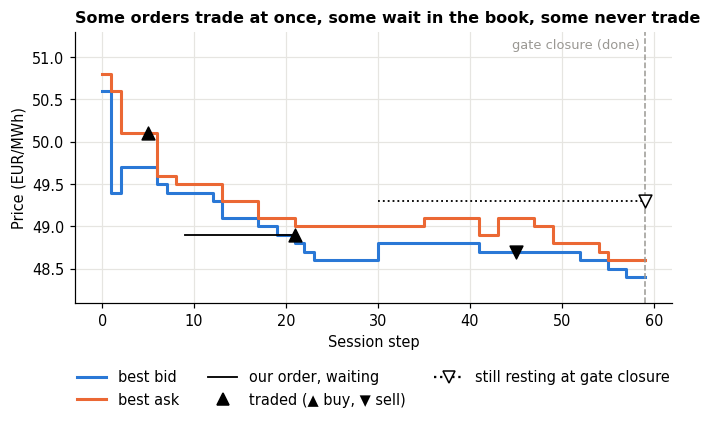

In [9]:
from matplotlib.lines import Line2D

bid, ask = np.array(touch).T
steps = np.arange(len(touch))
fig, ax = plt.subplots()
ax.step(steps, bid, where="post", color=BUY, lw=2)
ax.step(steps, ask, where="post", color=SELL, lw=2)
for o in orders.values():
    filled = o["end"] is not None
    end = o["end"] if filled else last_step
    ax.plot([o["step"], end], [o["price"]] * 2, color="black", lw=1.2, ls="-" if filled else ":")
    ax.scatter([end], [o["price"]], marker="^" if o["side"] == Side.BUY else "v", s=70, zorder=3,
               facecolor="black" if filled else "white", edgecolor="black")
top = np.nanmax(ask) + 0.5
ax.axvline(last_step, color=GREY, ls="--", lw=1)
ax.text(last_step - 0.5, top - 0.2, "gate closure (done)", ha="right", color=GREY, fontsize=8.5)
ax.set_ylim(np.nanmin(bid) - 0.3, top)
handles = [Line2D([], [], color=BUY, lw=2), Line2D([], [], color=SELL, lw=2), Line2D([], [], color="black", lw=1.2),
           Line2D([], [], ls="", marker="^", color="black", ms=8),
           Line2D([], [], ls=":", color="black", marker="v", mfc="white", mec="black", ms=8)]
ax.legend(handles, ["best bid", "best ask", "our order, waiting", "traded (▲ buy, ▼ sell)",
                    "still resting at gate closure"], loc="upper center", ncol=3, bbox_to_anchor=(0.5, -0.2))
ax.set_xlabel("Session step")
ax.set_ylabel("Price (EUR/MWh)")
ax.set_title("Some orders trade at once, some wait in the book, some never trade")
plt.show()

## 5. Cancelling an order between steps

The compiled step only submits. To cancel, call the book-level `ContractBook.cancel_order` between two
steps, with the order id from the `FillReport` and the order's side, and put the new book back into the
state. Here we send a sell far above the market at step 3 and cancel it at step 8.

In [10]:
state_c = session.reset(key).replace(tape_idx=jnp.int32(0))
for step in range(10):
    order = AgentOrder.create(side=Side.SELL, price=55.0, quantity=1.0) if step == 3 else None
    state_c, report, _ = session.step(key, state_c, order)
    if step == 3:
        my_order = int(report.order_id)
        print(f"after step 3: our resting orders {sorted(resting_ids(state_c))}")
    if step == 8:
        state_c = state_c.replace(book=book.cancel_order(state_c.book, my_order, Side.SELL))
        print(f"after the cancel at step 8: our resting orders {sorted(resting_ids(state_c))}")

after step 3: our resting orders [2000000003]


after the cancel at step 8: our resting orders []


Each order gets a new id, so keep the ids of the orders you may want to cancel. Cancelling an id that
no longer rests leaves the book unchanged.

## 6. Four pitfalls, and their fixes

### 6.1 The trade buffer can fill up

The book stores the session's trades in a buffer of fixed size, `nTrades` rows (100 by default), shared
by the tape and by you. When it is full, each new trade overwrites the last row. The book's trade record
is then incomplete, and the session, which reads that record to find your passive fills, can miss some
of them. `FillReport.trades_saturated` turns true when the buffer is full.

We play the busy tape (tape 1) with the same session and no orders of our own. The helper below runs a
session and notes the first step at which the buffer is full.

In [11]:
def run_quietly(sess, tape_idx, n_steps=None):
    # Play one tape without orders of our own, until done (or for n_steps steps).
    # Returns the final state, the number of steps and the first step with a full trade buffer.
    st = sess.reset(key).replace(tape_idx=jnp.int32(tape_idx))
    done, n, full_at = False, 0, None
    while (not done) if n_steps is None else n < n_steps:
        st, rep, done = sess.step(key, st, None)
        done = bool(done)
        if full_at is None and bool(rep.trades_saturated):
            full_at = n
        n += 1
    return st, n, full_at


n_busy = int((busy[:, 6] > 0).sum())
st_busy, steps_busy, full_at = run_quietly(session, 1)
print(f"busy tape: the buffer of {session.market_config.nTrades} trades is full from step {full_at}")

busy tape: the buffer of 100 trades is full from step 47


### 6.2 The default clock can reach gate closure before the last slice

The same run shows the second pitfall. With the `span_scaled` clock, `done` fires at the first slice
whose largest timestamp is within half a scaled minute of $S$, because the clock is rounded to whole
minutes: here, from $3600 \cdot 59.5 / 60 = 3570$ s on. The busy tape's closing rush starts at
3561 s, so `done` fires in the middle of the rush, and the orders after that slice are never replayed.

In [12]:
replayed = min(int(st_busy.tape_cursor), n_busy)
print(f"busy tape: done after {steps_busy} steps; {replayed} of {n_busy} orders replayed; "
      f"{n_busy - replayed} orders of the closing rush never reach the book")

busy tape: done after 53 steps; 212 of 240 orders replayed; 28 orders of the closing rush never reach the book


**The fixes.** Each one changes the session's configuration, and every new configuration compiles its
step again (about a minute), so we apply both in one new session:

- **Saturation:** set `nTrades` at least to the number of trades you expect in the session, with a
  margin. For a real contract, its number of published trades is a good guide, with a margin, because a replay
  can produce more trades than the real market did
  ([OQ-10](../docs/omiecid/open-questions.md#oq-10--cancelled-orders-not-identifiable-in-omie-public-data)).
  Treat a session whose buffer filled as unreliable. We take 400.
- **Early gate closure:** set `tape_seconds_span` to at least twice the largest timestamp of the whole
  tape set. The clock then never passes half of GCT, so `done` never fires; instead, play exactly
  `steps_per_episode` steps, which replays every row of the longest tape. Only the clock, `done` and the
  time column of your trade rows differ ([Limitations](../docs/limitations.md#early-gate-closure-under-the-span-scaled-clock)).

In [13]:
from omiecid_simulator.omiecid.omie_config import OMIEMarketConfig

largest = int(tapes[:, :, 6].max())
fixed = Session({"tapes": tapes, "orders_per_step": 4,
                 "market_config": OMIEMarketConfig(nTrades=400),  # room for every trade
                 "tape_seconds_span": 2 * largest})               # the clock never reaches gate closure
st_fixed, steps_fixed, full_fixed = run_quietly(fixed, 1, n_steps=fixed.steps_per_episode)
print(f"fixed session, busy tape: {steps_fixed} steps; buffer full: {full_fixed is not None}; "
      f"{min(int(st_fixed.tape_cursor), n_busy)} of {n_busy} orders replayed; clock ends at {int(st_fixed.time)} min")

fixed session, busy tape: 64 steps; buffer full: False; 240 of 240 orders replayed; clock ends at 30 min


The larger buffer removed the saturation, and the stretched clock let the whole closing rush through.
The clock now ends at 30 minutes and no longer marks gate closure: the end of the session is the step
count.

### 6.3 Orders still resting at `done` are not expired

In OMIE, unmatched orders are cancelled at gate closure ([market model](../docs/market-model.md#trading-window-and-gate-closure)).
The session stops at `done`, but it does not cancel your resting orders: they are still in the final
book. That does not change your cash or position, since an unfilled order never traded, but anything
that reads the book after `done` still sees them. The fix is `ContractBook.expire_at_gct`, which cancels
every order left in a book.

In [14]:
left = book.get_agent_orders(final.book, AGENT_TRADER_ID)
print(f"after done: {len(left)} of our orders still rest:",
      ", ".join(f"{'buy' if o.side == Side.BUY else 'sell'} {float(o.quantity):.1f} MW at {float(o.price):.2f}" for o in left))
expired = final.replace(book=book.expire_at_gct(final.book))
bids, asks = book.get_anonymous_lob(expired.book)
print(f"after expire_at_gct: {len(resting_ids(expired))} of our orders rest; "
      f"the book holds {len(bids)} bid and {len(asks)} ask levels")

after done: 1 of our orders still rest: sell 1.0 MW at 49.30


after expire_at_gct: 0 of our orders rest; the book holds 0 bid and 0 ask levels


### 6.4 Real data needs the `got_relative` clock

Real OMIE order files carry clock times: a loaded tape's timestamps are seconds after midnight of the
day before delivery, so gate opening (15:20) is 55,200 s ([T03](T03_real_data.ipynb) loads real files).
The default `span_scaled` clock assumes seconds after opening, and silently gets these tapes wrong.

To see it without downloading anything, we restamp the calm tape as real data: the same orders, now
sent from 22:00:00 to 22:59:45 on the day before delivery. We take the contract delivered from 00:00 to
00:15. Its gate closure is 23:00, that is $460 + 60\lfloor k/4 \rfloor = 460$ minutes after opening for
contract $k = 0$. (One more simplification: in the real market no
order is sent between 22:00 and 22:20, while the second intraday auction runs. Our made-up tape
ignores that pause.)

In [15]:
GOT_SECONDS = 15 * 3600 + 20 * 60  # gate opening, 15:20, in seconds after midnight of the day before delivery
real_like = calm.copy()
sent = real_like[:, 6] > 0
real_like[sent, 6] += 22 * 3600 - 15  # first order at 22:00:00, last at 22:59:45


def clock_time(minutes_after_opening):
    # Minutes after gate opening as a clock time on the day before delivery.
    m = GOT_SECONDS // 60 + int(minutes_after_opening)
    return f"{m // 60 % 24:02d}:{m % 60:02d}"


print(f"first order {clock_time((real_like[sent, 6].min() - GOT_SECONDS) // 60)}, "
      f"last order {clock_time((real_like[sent, 6].max() - GOT_SECONDS) // 60)}")

first order 22:00, last order 22:59


**What the default clock would do.** Running a session on this tape would cost another compile, so we
compute its clock directly, slice by slice, from the `span_scaled` formula of section 2 with the default
gate closure of 60 minutes. We first check the formula against the clock the session recorded in section 4.

In [16]:
def span_scaled_clock(tape, orders_per_step=4, gct=60):
    # The default clock after each step, from its formula: t_k = max(t_(k-1), round(m_k * gct / S)).
    ts = tape[:, 6].reshape(-1, orders_per_step)
    m = np.where(ts > 0, ts, -1).max(axis=1)  # the largest timestamp of each slice (-1: padding only)
    span = max(int(tape[:, 6].max()), 1)      # S: the largest timestamp
    return np.maximum.accumulate(np.where(m >= 0, np.round(m * gct / span), 0))


assert np.array_equal(span_scaled_clock(calm)[:len(clock_main)], clock_main)  # the formula is the session's clock
print(f"the formula reproduces the session's clock at all {len(clock_main)} steps of section 4")

t_default = span_scaled_clock(real_like)
n_real = int(sent.sum())
ops = session.orders_per_step
true_first = (int(real_like[:ops, 6].max()) - GOT_SECONDS) // 60
done_step = int(np.argmax(t_default >= 60))
print(f"default clock after the first step: {t_default[0]:.0f} min after opening "
      f"(true: {true_first} min, {clock_time(true_first)})")
print(f"done at step {done_step}: {ops * (done_step + 1)} of {n_real} orders replayed, "
      f"{n_real - ops * (done_step + 1)} never")

the formula reproduces the session's clock at all 60 steps of section 4
default clock after the first step: 57 min after opening (true: 400 min, 22:00)
done at step 48: 196 of 240 orders replayed, 44 never


The clock reads 57 minutes after the first step, close to the 60-minute gate closure it assumes,
instead of 22:00. `done` then fires early: the last 44 orders, about 11 minutes of trading, never reach
the book. No error is raised: that is what makes this pitfall dangerous.

**The fix** is `session_clock="got_relative"`, with the contract's gate closure and gate opening. With
the default gate closure of 60 minutes, the constructor refuses this tape, because its orders lie after
that gate closure:

In [17]:
try:
    Session({"tapes": real_like[None], "session_clock": "got_relative"})
except ValueError as err:
    print("ValueError:", str(err).split(";")[1].strip())

ValueError: gct_minutes_from_got=60 does not match the loaded contract (no row can be sent at or after GCT)


In [18]:
real = Session({"tapes": real_like[None], "orders_per_step": 4, "session_clock": "got_relative",
                "gct_minutes_from_got": 460, "got_seconds": GOT_SECONDS})
st_real = real.reset(key)
clock = []
done = False
while not done:  # the first step compiles the third configuration of this tutorial
    st_real, _, done = real.step(key, st_real, None)
    done = bool(done)
    clock.append(int(st_real.time))
print(f"first step {clock_time(clock[0])}, last slice of orders {clock_time(clock[-2])}, "
      f"done at {clock_time(clock[-1])} after {len(clock)} steps")
print(f"orders replayed: {min(int(st_real.tape_cursor), n_real)} of {n_real}")

first step 22:00, last slice of orders 22:59, done at 23:00 after 61 steps
orders replayed: 240 of 240


The clock now shows the real time of day and every order is replayed. Under `got_relative`, `done`
fires when the tape runs out: the clock then jumps to gate closure (23:00), whatever the time of the
last order. Here the last order is at 22:59:45, so the two coincide. On a tape whose orders stop
earlier, the session ends after the last slice, and you cannot trade in the minutes between the last
tape order and the real gate closure.

## Recap

- A `Session` replays a tape into one contract's book and adds your orders after each slice, behind
  every earlier arrival at the same price.
- The clock runs in minutes after gate opening; `done` marks gate closure, and calls after it are ignored.
- `FillReport` tells you what your new order did and which of your resting orders traded;
  `top_of_book` gives the anonymous touch. Cancel between steps with `ContractBook.cancel_order`.
- Check `trades_saturated`; replay a whole synthetic tape with `tape_seconds_span` ≥ 2 × the largest
  timestamp; expire leftover orders with `expire_at_gct`; use `got_relative` for real data.

## Exercises

1. **An order that must trade at once.** At step 10 of the calm tape, send an immediate-or-cancel (IOC)
   buy 0.50 EUR/MWh *below* the best ask. Does it trade? Does anything rest? *Hint:* pass
   `exec_restriction=ExecRestriction.IOC` to `AgentOrder.create`, then read `report.submit` and
   `resting_ids`.
2. **Tidy up before gate closure.** Replay section 4, but cancel the step-30 sell at step 50. Check that
   none of your orders rests at `done`. *Hint:* section 5.
3. **When does the rush end the session?** Play the busy tape with the first session and print the clock
   of the last five steps. At which step does it jump to 60 minutes? *Hint:* `state.time` after each step.

The solutions are in the collapsed cell at the end.

## Further reading

- [Sessions](../docs/sessions.md): every field of `AgentOrder`, `FillReport` and the state, the clocks, and batching.
- [Limitations](../docs/limitations.md) and [the market model](../docs/market-model.md).
- The evidence: [the market specification](../docs/omiecid/market-spec.md) (gate times in [§3.1](../docs/omiecid/market-spec.md#31-continuous-market-gate-times)) and [the certificate](../docs/omiecid/certificate.md) ([C11](../notebooks/certification/C11_gct_expiry.ipynb) certifies expiry at gate closure).
- Next tutorial: [T06 — Writing an agent](T06_writing_an_agent.ipynb). Real data: [T03](T03_real_data.ipynb).

## Solutions

In [19]:
# Solutions to the exercises (collapsed; expand to read).
from omiecid_simulator.omiecid.order_types import ExecRestriction

# 1. An IOC buy below the best ask finds no seller at its price: it is accepted, trades nothing,
#    and its whole quantity is cancelled instead of resting.
st = session.reset(key).replace(tape_idx=jnp.int32(0))
for step in range(11):
    order = None
    if step == 10:
        tob = session.top_of_book(st)
        order = AgentOrder.create(side=Side.BUY, price=round(float(tob.p_ask) - 0.5, 2), quantity=1.0,
                                  exec_restriction=ExecRestriction.IOC)
    st, rep, _ = session.step(key, st, order)
print(f"1. accepted {bool(rep.submit.accepted)}, traded {bool(rep.submit.traded)}, "
      f"resting orders {len(resting_ids(st))}")

# 2. Section 4 with a cancel at step 50.
st, done, step, sell_id = session.reset(key).replace(tape_idx=jnp.int32(0)), False, 0, None
while not done:
    tob = session.top_of_book(st)
    order = None
    if step in plan:
        side, reference, offset = plan[step]
        limit = (float(tob.p_ask) if reference == "ask" else float(tob.p_bid)) + offset
        order = AgentOrder.create(side=side, price=round(limit, 2), quantity=1.0)
    st, rep, done = session.step(key, st, order)
    done = bool(done)
    if step == 30:
        sell_id = int(rep.order_id)
    if step == 50:
        st = st.replace(book=book.cancel_order(st.book, sell_id, Side.SELL))
    step += 1
print(f"2. orders resting at done: {len(resting_ids(st))}")

# 3. The clock of the busy tape's last steps.
st, clocks, done = session.reset(key).replace(tape_idx=jnp.int32(1)), [], False
while not done:
    st, _, done = session.step(key, st, None)
    done = bool(done)
    clocks.append(int(st.time))
print(f"3. last five steps: " + ", ".join(f"step {len(clocks) - 5 + i}: {c} min" for i, c in enumerate(clocks[-5:])))

1. accepted True, traded False, resting orders 0


2. orders resting at done: 0
3. last five steps: step 48: 49 min, step 49: 50 min, step 50: 59 min, step 51: 59 min, step 52: 60 min
